# Results

The quarter's results, read from `output/`, in tables and two charts for the README. The last section, **Look inside**,
runs the pipeline in this notebook so any intermediate table can be queried, and follows one ledger line from start to
end.

- Run `python run.py` from the repo root first, so `output/` is current.
- This notebook reads the results; it doesn't change them. Tables built here from `allocation.csv` add up rounded rows,
  so they can differ from the summaries by a few cents (D05).
- IDs (R01 rules, D01 decisions, I01 data issues, ...) are explained in [`docs/design.md`](../docs/design.md#ids).

## Setup

In [13]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter, MultipleLocator

ROOT = Path("..").resolve()
OUTPUT = ROOT / "output"
IMG = ROOT / "docs" / "img"
IMG.mkdir(exist_ok=True)

summary = pd.read_csv(OUTPUT / "summary.csv")
summary_by_entity = pd.read_csv(OUTPUT / "summary_by_entity.csv")
reconciliation = pd.read_csv(OUTPUT / "reconciliation.csv")
allocation = pd.read_csv(OUTPUT / "allocation.csv")
entities = pd.read_csv(ROOT / "data" / "entities.csv", dtype=str)

# The quarter row is the one labelled like 2026-Q1; the label comes from the data, not from here
is_quarter = summary["period"].str.contains("-Q")
quarter = summary.loc[is_quarter, "period"].iloc[0]

pd.options.display.float_format = "{:,.2f}".format

# Chart style: one color per side, the same in both charts (checked for color-blind readers)
BR_GAMES, US_GAMES = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e2dc", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False,
})
millions = FuncFormatter(lambda v, _: f"{v / 1e6:.1f} M")

FileNotFoundError: [Errno 2] No such file or directory: '/home/felipi/Projects/wildlife/delivery/docs/img'

## The quarter

Where every ledger dollar went (R11). Same numbers as `output/reconciliation.csv`.

In [ ]:
reconciliation.set_index("period")

,ledger_total,out_of_scope,in_scope,allocated,unallocated,difference
period,,,,,,
2026-01,"2,199,715.43","32,788.59","2,166,926.84","2,166,926.84",0.00,0.00
2026-02,"2,208,574.52","32,596.44","2,175,978.08","2,158,960.10","17,017.98",0.00
2026-03,"2,229,005.81","32,659.88","2,196,345.93","2,181,307.94","15,037.99",0.00
2026-Q1,"6,637,295.76","98,044.91","6,539,250.85","6,507,194.88","32,055.97",0.00


**Result:** in 2026-Q1 the ledger has 6,637,295.76 USD: 98,044.91 USD out of scope, 6,507,194.88 USD allocated and
32,055.97 USD unallocated (I01, I03). The difference is 0.00 USD in every period.

### The quarter by side

The headline for Tax: how much of the allocated cost each side bears. From `output/summary.csv`, quarter rows.

In [ ]:
by_side = summary[is_quarter][["br_games", "us_games", "unallocated"]].sum()
pd.DataFrame({"amount_usd": by_side, "share_of_in_scope": by_side / by_side.sum()})

,amount_usd,share_of_in_scope
br_games,"4,642,414.76",0.71
us_games,"1,864,780.12",0.29
unallocated,"32,055.97",0.00


**Result:** BR Games bears 4,642,414.76 USD (71% of the in-scope cost) and US Games 1,864,780.12 USD (29%);
32,055.97 USD (0.5%) has no side yet.

### Who bears the quarter's cost, by booked group

From `output/summary.csv`, quarter rows. Unallocated dollars have no side, so they are left out of the chart and
named in its subtitle.

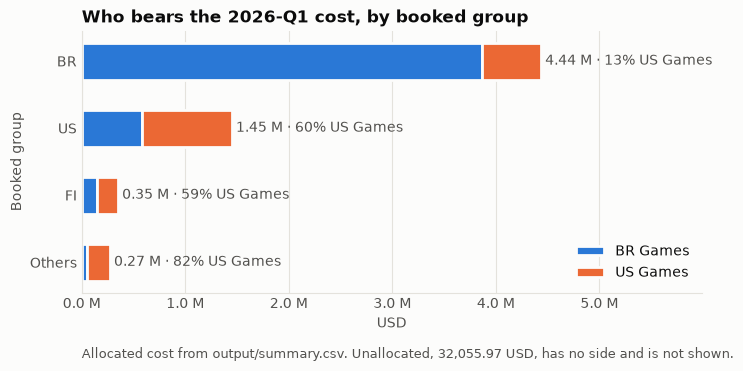

,booked_group,br_games,us_games,unallocated,total
12,BR,"3,865,691.60","570,224.08","27,853.72","4,463,769.40"
15,US,"583,080.12","866,375.87","3,304.64","1,452,760.63"
13,FI,"145,078.73","205,052.25",573.84,"350,704.82"
14,Others,"48,564.31","223,127.92",323.77,"272,016.00"


In [ ]:
q = summary[is_quarter].copy()
q["allocated"] = q["br_games"] + q["us_games"]
q["us_share"] = q["us_games"] / q["allocated"]
q = q.sort_values("allocated")  # largest at the top of the chart

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(q["booked_group"], q["br_games"], height=0.55, color=BR_GAMES, edgecolor=SURFACE, linewidth=2,
        label="BR Games")
ax.barh(q["booked_group"], q["us_games"], left=q["br_games"], height=0.55, color=US_GAMES, edgecolor=SURFACE,
        linewidth=2, label="US Games")
for _, row in q.iterrows():
    ax.text(row["allocated"] + 40_000, row["booked_group"],
            f"{row['allocated'] / 1e6:.2f} M · {row['us_share']:.0%} US Games", va="center", color=MUTED)

ax.xaxis.set_major_formatter(millions)
ax.set_xlim(0, q["allocated"].max() * 1.35)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_xlabel("USD")
ax.set_ylabel("Booked group")
ax.legend(loc="lower right", frameon=False)
ax.set_title(f"Who bears the {quarter} cost, by booked group", loc="left", fontweight="bold")
fig.text(0.0, -0.25, f"Allocated cost from output/summary.csv. Unallocated, {q['unallocated'].sum():,.2f} USD, "
         "has no side and is not shown.", color=MUTED, fontsize=9, transform=ax.transAxes)
fig.savefig(IMG / "quarter-by-booked-group.png", dpi=150, bbox_inches="tight", metadata={"Software": None})
plt.show()

q[["booked_group", "br_games", "us_games", "unallocated", "total"]].sort_values("total", ascending=False)

**Result:** the BR group booked most of the cost, 4,463,769.40 USD, and BR Games bears 87% of what was allocated
from it. Every other group leans to US Games: US 60%, FI 59%, Others 82%.

## By month

### Allocated cost by side and month

From `output/summary.csv`, the three month rows of each booked group, added up.

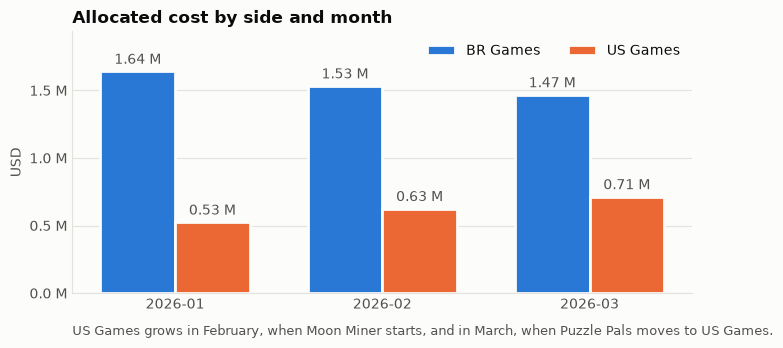

,br_games,us_games
period,,
2026-01,"1,641,493.80","525,433.04"
2026-02,"1,533,249.68","625,710.42"
2026-03,"1,467,671.27","713,636.68"


In [ ]:
months = summary[~is_quarter].groupby("period")[["br_games", "us_games"]].sum()

fig, ax = plt.subplots(figsize=(8, 3.4))
x = range(len(months))
width = 0.36
bars_br = ax.bar([i - width / 2 for i in x], months["br_games"], width, color=BR_GAMES, edgecolor=SURFACE,
                 linewidth=2, label="BR Games")
bars_us = ax.bar([i + width / 2 for i in x], months["us_games"], width, color=US_GAMES, edgecolor=SURFACE,
                 linewidth=2, label="US Games")
for bars in (bars_br, bars_us):
    ax.bar_label(bars, labels=[f"{v / 1e6:.2f} M" for v in bars.datavalues], padding=3, color=MUTED)

ax.set_xticks(list(x), months.index)
ax.yaxis.set_major_formatter(millions)
ax.yaxis.set_major_locator(MultipleLocator(500_000))
ax.set_ylim(0, months.to_numpy().max() * 1.18)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_ylabel("USD")
ax.legend(loc="upper right", frameon=False, ncols=2)
ax.set_title("Allocated cost by side and month", loc="left", fontweight="bold")
fig.text(0.0, -0.16, "US Games grows in February, when Moon Miner starts, and in March, when Puzzle Pals moves to US Games.",
         color=MUTED, fontsize=9, transform=ax.transAxes)
fig.savefig(IMG / "side-by-month.png", dpi=150, bbox_inches="tight", metadata={"Software": None})
plt.show()

months

### What changed month to month

Allocated amount by game or bucket and side, from `output/allocation.csv`, and the change from the month before. The
rows that moved most come first.

In [ ]:
allocated = allocation[allocation["status"] == "allocated"]
by_month = allocated.pivot_table(index=["side", "game_or_bucket"], columns="month", values="amount_usd",
                                 aggfunc="sum", fill_value=0)
month_list = list(by_month.columns)
for before, after in zip(month_list, month_list[1:]):
    by_month[f"change {after}"] = by_month[after] - by_month[before]
change_cols = [c for c in by_month.columns if str(c).startswith("change")]
by_month.loc[by_month[change_cols].abs().max(axis=1).sort_values(ascending=False).index].head(8)

month                      2026-01    2026-02    2026-03  change 2026-02  \
side     game_or_bucket                                                    
US Games Moon Miner           0.00 114,538.78 120,477.15      114,538.78   
         Puzzle Pals          0.00       0.00 106,298.56            0.00   
BR Games Puzzle Pals     99,215.49  97,871.30       0.00       -1,344.19   
         Kingdom Clash  302,706.84 251,615.50 301,516.05      -51,091.34   
         live_br        557,170.43 506,859.02 526,329.56      -50,311.41   
         Star Racer     252,473.50 271,309.41 230,137.25       18,835.91   
US Games Pixel Farm     185,784.20 179,811.95 157,581.16       -5,972.25   
BR Games new_br         198,989.46 178,471.47 195,493.91      -20,517.99   

month                    change 2026-03  
side     game_or_bucket                  
US Games Moon Miner            5,938.37  
         Puzzle Pals         106,298.56  
BR Games Puzzle Pals         -97,871.30  
         Kingdom Clash        49,900.55  
         live_br              19,470.54  
         Star Racer          -41,172.16  
US Games Pixel Farm          -22,230.79  
BR Games new_br               17,022.44

**Result:** two games explain the jumps in US Games.
- February: Moon Miner starts, +114,538.78 USD to US Games. It has no FTE and no mapping row in January (C10).
- March: Puzzle Pals moves from BR Games to US Games on 2026-03-01 (R10, W05): −97,871.30 USD in BR Games and
  +106,298.56 USD in US Games compared with February.

The other rows change by less, as costs vary from month to month (Kingdom Clash, live_br, Star Racer).

### Direct and indirect

Indirect costs are split by headcount, so they are the part that depends on Q04. From the allocated rows of
`output/allocation.csv`.

In [ ]:
by_type = allocated.pivot_table(index="cost_type", columns="side", values="amount_usd", aggfunc="sum")
by_type["Total"] = by_type.sum(axis=1)
by_type

side,BR Games,US Games,Total
cost_type,,,
direct,"2,479,101.05","1,270,028.69","3,749,129.74"
indirect,"2,163,313.85","594,751.54","2,758,065.39"


**Result:** 2,758,065.39 USD of the allocated cost is indirect (42%). Reading Q04 the other way would give BR Games
about 180,980 USD less and US Games about 188,845 USD more in the quarter (S18).

## For Tax: booked entity and bearing group

The BRIEF says Tax needs to know, every month, how much cost each entity booked and which side bears it. That is
`output/summary_by_entity.csv`; here the quarter rows, with the entity names. `summary.csv` adds these rows up by
booked group, so LGC and LGK are both in Others there.

In [ ]:
by_entity = summary_by_entity[summary_by_entity["period"] == quarter].set_index("booked_entity")
names = entities.set_index("entity")["entity_name"]
by_entity.join(names).sort_values("total", ascending=False)[
    ["entity_name", "booked_group", "br_games", "us_games", "unallocated", "total"]]

,entity_name,booked_group,br_games,us_games,unallocated,total
booked_entity,,,,,,
LGB,Lumen Games Brasil Ltda,BR,"3,865,691.60","570,224.08","27,853.72","4,463,769.40"
LGI,Lumen Games Inc,US,"583,080.12","866,375.87","3,304.64","1,452,760.63"
LGF,Lumen Games Finland Oy,FI,"145,078.73","205,052.25",573.84,"350,704.82"
LGK,Lumen Games UK Ltd,Others,"30,889.89","159,870.58",205.76,"190,966.24"
LGC,Lumen Games Canada Ltd,Others,"17,674.42","63,257.34",118.01,"81,049.76"


**Result:** LGB booked the most, and BR Games bears most of it. LGC and LGK, the two entities in Others, lean
strongly to US Games. Every entity has some unallocated dollars: I03 (live_fi) takes a piece of every March indirect
line, whatever entity booked it.

### Whose cost each group bears

Allocated rows of `output/allocation.csv`: booked group (rows) × bearing group (columns). The diagonal stays in the
group that booked it; off the diagonal is cost booked by one group and borne by another. Only indirect costs cross
groups: a direct cost keeps the booked group (R06); an indirect piece takes its bucket's bearing group (R09).

In [ ]:
allocated.pivot_table(index="booked_group", columns="bearing_group", values="amount_usd", aggfunc="sum",
                      fill_value=0)

bearing_group,BR,FI,Others,US
booked_group,,,,
BR,"4,010,933.50","129,360.01","80,850.03","214,772.37"
FI,"83,316.06","250,880.42","4,355.41","11,579.12"
Others,"48,564.28","4,059.81","212,270.06","6,798.06"
US,"484,917.59","40,550.99","25,344.39","898,643.03"


**Result:** the largest crossing is cost booked by the US group and borne by the BR group, 484,917.59 USD. The other
way, cost booked by the BR group and borne by the US group is 214,772.37 USD.

## Look inside

Runs the same SQL files as `run.py`, in name order, in this notebook. Every table of the pipeline is then here to query
(see [Pipeline](../docs/design.md#pipeline)). Nothing is written to `output/`.

In [ ]:
import os

os.chdir(ROOT)  # the SQL reads data/ from the repo root, as run.py does
pd.options.display.float_format = None  # full precision from here on: shares are not cents
con = duckdb.connect()
for step in sorted(Path("sql").glob("*.sql")):
    con.execute(step.read_text())

con.sql("SELECT table_name, estimated_size AS rows FROM duckdb_tables() ORDER BY table_name").df()

,table_name,rows
0,accounts,9
1,allocation,2155
2,bucket_shares,16
3,cost_centers,22
4,employee_buckets,368
5,entities,5
6,game_mapping,16
7,headcount_employees,368
8,headcount_games,26
9,ledger,646


### Follow one line

W03: L00444, an indirect line of February. Change `line` to follow any other.

In [ ]:
line = "L00444"
con.sql(f"SELECT line_id, month, booked_entity, booked_group, cost_center, department, cost_type, amount_usd, line_reason FROM lines WHERE line_id = '{line}'").df()

,line_id,month,booked_entity,booked_group,cost_center,department,cost_type,amount_usd,line_reason
0,L00444,2026-02,LGB,BR,3301,Operations,indirect,21346.02,None


In [ ]:
# Its pieces with their mapping row (07_mapping.sql), at full precision
con.sql(f"SELECT * FROM pieces_mapped WHERE line_id = '{line}' ORDER BY game_or_bucket").df()

,line_id,game_or_bucket,share,reason,bearing_group,side
0,L00444,live_br,0.577236,None,BR,BR Games
1,L00444,new_br,0.203252,None,BR,BR Games
2,L00444,new_fi,0.065041,None,FI,US Games
3,L00444,new_others,0.040650,None,Others,US Games
4,L00444,new_us,0.113821,None,US,US Games


In [ ]:
# The same pieces as written to allocation.csv (11_output.sql rounds them)
con.sql(f"SELECT line_id, game_or_bucket, share, amount_usd, bearing_group, side, status, reason FROM output_allocation WHERE line_id = '{line}'").df()

,line_id,game_or_bucket,share,amount_usd,bearing_group,side,status,reason
0,L00444,live_br,0.577236,12321.69,BR,BR Games,allocated,None
1,L00444,new_br,0.203252,4338.62,BR,BR Games,allocated,None
2,L00444,new_fi,0.065041,1388.36,FI,US Games,allocated,None
3,L00444,new_others,0.040650,867.72,Others,US Games,allocated,None
4,L00444,new_us,0.113821,2429.63,US,US Games,allocated,None


### Any question

Write any SQL against the pipeline's tables. For example: where the unallocated dollars are, by reason and month.

In [ ]:
con.sql("""
    SELECT reason, month, COUNT(*) AS rows, SUM(amount_usd) AS amount_usd
    FROM allocation
    WHERE status = 'unallocated'
    GROUP BY reason, month
    ORDER BY reason, month
""").df()

,reason,month,rows,amount_usd
0,no_mapping_row,2026-03,82,15037.98816
1,unknown_cost_center,2026-02,1,17017.98000
